In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/raw.csv', parse_dates=['Date'])
df = df.sort_values('Date').set_index('Date')

print("Data loaded!")
print(f"Shape    : {df.shape}")
print(f"Periode  : {df.index.min().date()} → {df.index.max().date()}")
print(f"Kolom    : {list(df.columns)}")

Data loaded!
Shape    : (4277, 9)
Periode  : 2010-01-01 → 2026-05-29
Kolom    : ['OIL', 'GOLD', 'USDIDR', 'SP500', 'IHSG', 'VIX', 'CPI', 'BI_rate', 'US_rate']


In [3]:
# Cek jumlah dan persentase data yang kosong (NaN)
missing = df.isna().sum().to_frame('missing_count')
missing['missing_pct'] = (missing['missing_count'] / len(df) * 100).round(2)

print("MISSING VALUES:")
print(missing.sort_values('missing_count', ascending=False))

MISSING VALUES:
         missing_count  missing_pct
OIL                  1         0.02
GOLD                 1         0.02
SP500                1         0.02
IHSG                 1         0.02
VIX                  1         0.02
USDIDR               0         0.00
CPI                  0         0.00
BI_rate              0         0.00
US_rate              0         0.00


In [5]:
print("--- Audit 1: Deteksi Bug Desimal USDIDR ---")
bug_usdidr = df[df['USDIDR'] < 5000]
print(f"Jumlah baris USDIDR < 5000: {len(bug_usdidr)}")
if not bug_usdidr.empty:
    print(bug_usdidr['USDIDR'])

print("\n--- Audit 2: Deteksi Harga Stale (Nilai Sama) ---")
for col in ['IHSG', 'USDIDR', 'OIL']:
    stale_days = (df[col].diff() == 0).sum()
    print(f"{col:8s}: {stale_days:4d} hari")

print("\n--- Audit 3: Deteksi Hari Libur (Forward-Filled) ---")
ff_mask = (df['OIL'].diff() == 0) & (df['SP500'].diff() == 0) & (df['VIX'].diff() == 0)
print(f"Jumlah hari forward-filled: {ff_mask.sum()}")

--- Audit 1: Deteksi Bug Desimal USDIDR ---
Jumlah baris USDIDR < 5000: 2
Date
2010-11-01    888.109985
2012-02-07    892.000000
Name: USDIDR, dtype: float64

--- Audit 2: Deteksi Harga Stale (Nilai Sama) ---
IHSG    :  300 hari
USDIDR  :  102 hari
OIL     :  164 hari

--- Audit 3: Deteksi Hari Libur (Forward-Filled) ---
Jumlah hari forward-filled: 147


In [6]:
# Perbaiki bug desimal USDIDR (kalikan 10 jika nilainya < 5000)
bug_mask = df['USDIDR'] < 5000
df.loc[bug_mask, 'USDIDR'] = df.loc[bug_mask, 'USDIDR'] * 10

# Hapus baris pertama yang kosong (2010-01-01) berdasarkan data aset global
df_clean = df.dropna(subset=['OIL', 'GOLD', 'SP500', 'IHSG', 'VIX']).copy()

# Flag untuk mengidentifikasi IHSG yang stale (berpotensi untuk feature engineering)
df_clean['IHSG_stale'] = (df_clean['IHSG'].diff() == 0).astype(int)

print("Data cleaning selesai.")
print(f"Total baris sebelum: {len(df)}")
print(f"Total baris sesudah: {len(df_clean)}")
print(f"Sisa baris USDIDR anomali: {len(df_clean[df_clean['USDIDR'] < 5000])}")

Data cleaning selesai.
Total baris sebelum: 4277
Total baris sesudah: 4276
Sisa baris USDIDR anomali: 0


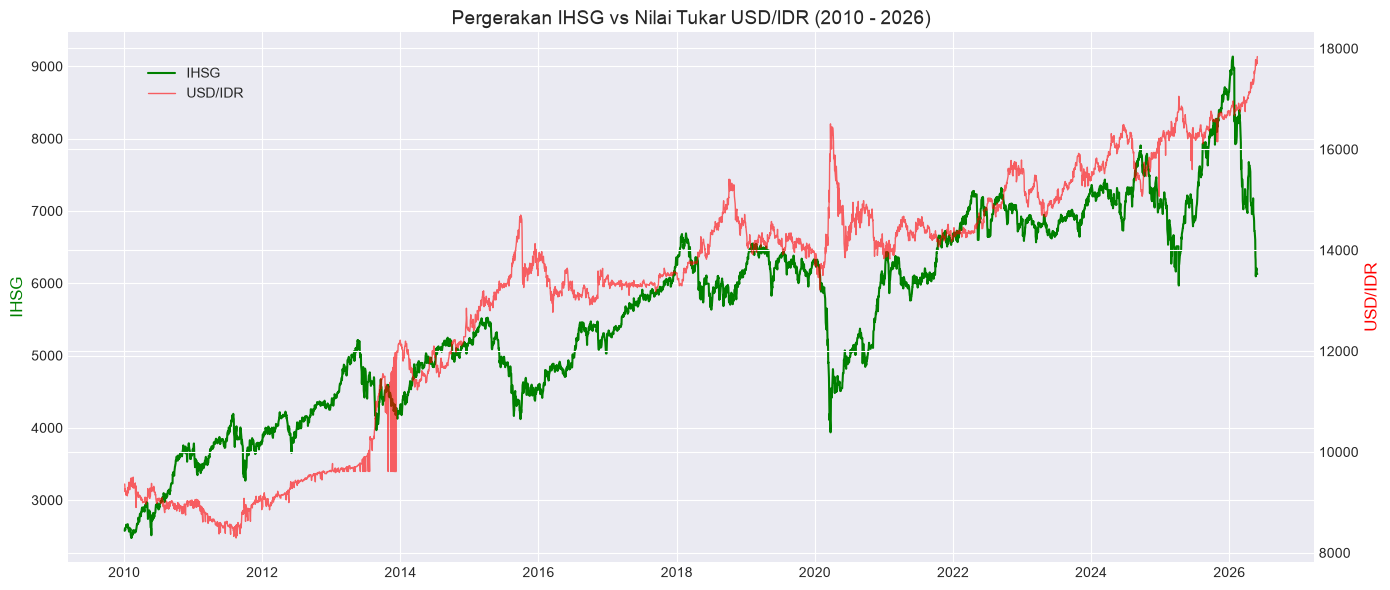

In [7]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-darkgrid')

fig, ax1 = plt.subplots(figsize=(14, 6))

# Sumbu Y kiri untuk IHSG
ax1.plot(df_clean.index, df_clean['IHSG'], color='green', label='IHSG', linewidth=1.5)
ax1.set_ylabel('IHSG', color='green', fontsize=12)

# Sumbu Y kanan untuk USD/IDR
ax2 = ax1.twinx()
ax2.plot(df_clean.index, df_clean['USDIDR'], color='red', alpha=0.6, label='USD/IDR', linewidth=1)
ax2.set_ylabel('USD/IDR', color='red', fontsize=12)

plt.title('Pergerakan IHSG vs Nilai Tukar USD/IDR (2010 - 2026)', fontsize=14)
fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.9))

plt.tight_layout()
plt.show()

In [8]:
# Simpan data yang sudah dibersihkan ke dalam file CSV
df_clean.to_csv('../data/clean_data.csv', index=True)
print("Data bersih berhasil disimpan ke data/clean_data.csv")

Data bersih berhasil disimpan ke data/clean_data.csv
